# 01 — Exploration : un bureau, ses cycles et sa relation à la température

**Données** : Building Data Genome Project 2 (BDG2), compteurs électriques horaires 2016–2017.
**Bâtiment** : `Fox_office_Brandy` — bureau universitaire, 3 922 m², Tempe (Arizona), construit en 1985.

Questions :
1. Quelle est la qualité des données (trous, zéros, valeurs aberrantes, fuseau horaire) ?
2. Quels cycles voit-on (jour/nuit, semaine/week-end, saisons, jours fériés) ?
3. Comment la consommation dépend-elle de la température extérieure (signature énergétique) ?

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import changepoint
from src.data import load_building, load_metadata
from src.metrics import report

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
BUILDING = "Fox_office_Brandy"

## 1. Métadonnées et chargement

In [2]:
meta = load_metadata()
meta.loc[BUILDING].dropna()

site_id                                 Fox
building_id_kaggle                    274.0
site_id_kaggle                          2.0
primaryspaceusage                    Office
sub_primaryspaceusage                Office
sqm                                  3921.8
sqft                                42214.0
lat                               33.424425
lng                              -111.92814
timezone                        US/Mountain
electricity                             Yes
industry                          Education
subindustry              College/University
yearbuilt                            1985.0
Name: Fox_office_Brandy, dtype: object

In [3]:
df = load_building(BUILDING)
df[["kwh", "airTemperature", "dewTemperature", "windSpeed"]].describe().round(1)

,kwh,airTemperature,dewTemperature,windSpeed
count,17534.0,17542.0,17542.0,17531.0
mean,32.2,25.1,4.0,2.9
std,21.9,9.1,7.6,1.9
min,1.7,2.2,-19.4,0.0
25%,15.6,17.8,-1.7,1.5
50%,22.9,25.6,3.3,2.6
75%,42.4,32.2,8.9,4.1
max,115.6,48.3,24.4,15.4


## 2. Qualité des données

Avant toute modélisation : combien d'heures manquantes, de zéros, et y a-t-il des
plateaux suspects (compteur figé) ?

In [4]:
s = df["kwh"]
print(f"Période         : {s.index.min():%Y-%m-%d} → {s.index.max():%Y-%m-%d}")
print(f"Heures          : {len(s):,}")
print(f"Manquants       : {s.isna().sum()} h ({s.isna().mean():.2%})")
print(f"Zéros           : {(s == 0).sum()} h")
print(f"Météo manquante : {df['airTemperature'].isna().sum()} h")

# Plateaux : même valeur répétée >= 6 h d'affilée (compteur figé ?)
runs = (s != s.shift()).cumsum()
run_len = s.groupby(runs).transform("size")
print(f"Heures dans un plateau >= 6 h : {(run_len >= 6).sum()}")

Période         : 2016-01-01 → 2017-12-31
Heures          : 17,544
Manquants       : 10 h (0.06%)
Zéros           : 0 h
Météo manquante : 2 h
Heures dans un plateau >= 6 h : 0


**Piège de l'agrégation journalière** : `resample("D").sum()` compte les heures
manquantes comme 0. Un jour incomplet paraît donc artificiellement bas et peut
ressembler à une anomalie. On utilise `sum(min_count=24)` : la somme vaut NaN
s'il manque ne serait-ce qu'une heure.

In [5]:
hours_per_day = s.resample("D").count()
incomplete = hours_per_day[hours_per_day < 24]
pd.DataFrame(
    {
        "heures présentes": incomplete,
        "sum() naïf [kWh]": s.resample("D").sum()[incomplete.index].round(0),
        "sum(min_count=24)": s.resample("D").sum(min_count=24)[incomplete.index],
    }
)

,heures présentes,sum() naïf [kWh],sum(min_count=24)
timestamp,,,
2016-03-23,23,507.0,NaN
2016-11-23,17,494.0,NaN
2017-04-09,23,357.0,NaN
2017-12-28,23,528.0,NaN


## 3. Fuseau horaire et heure d'été

Les timestamps BDG2 sont en heure locale. **L'Arizona n'applique pas l'heure d'été**
(fuseau `America/Phoenix`, UTC−7 toute l'année). Si les données étaient décalées,
l'heure de démarrage du bâtiment sauterait d'une heure le 13 mars et le 6 novembre 2016
(dates du changement d'heure aux États-Unis).

On vérifie : pour chaque jour ouvré, l'**heure de démarrage**, définie comme la
première heure (entre 3 h et 12 h) où la consommation augmente de plus de 15 % de
l'amplitude du jour.

*Pourquoi pas simplement l'heure de la plus forte hausse ?* Parce que ce bâtiment
démarre en deux marches (6 h : CVC, 8 h : occupants). Selon les mois, la marche de 8 h
est la plus forte, et cet indicateur saute de 6 h à 8 h sans rapport avec l'heure d'été.

Heure de démarrage la plus fréquente, par mois : [6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6]


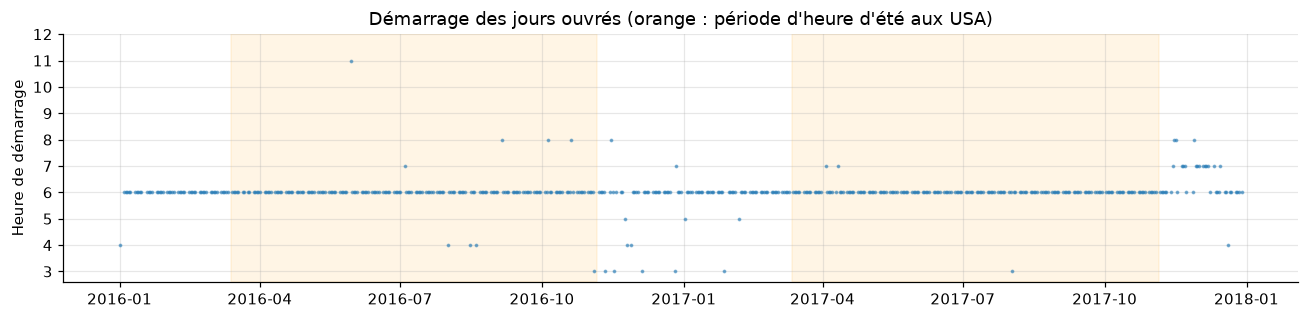

In [6]:
def start_hour(d, frac=0.15):
    if d.notna().sum() < 24:
        return np.nan
    jump = d.diff().to_numpy()
    threshold = frac * (d.max() - d.min())
    for h in range(3, 13):
        if jump[h] > threshold:
            return h
    return np.nan


workdays = s[s.index.day_of_week < 5]
start = workdays.groupby(workdays.index.date).apply(start_hour)
start.index = pd.to_datetime(start.index)
monthly_mode = start.groupby(start.index.to_period("M")).agg(lambda x: x.mode()[0])
print(
    "Heure de démarrage la plus fréquente, par mois :",
    monthly_mode.astype(int).tolist(),
)

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(start.index, start, ".", ms=3, alpha=0.5)
for a, b in [("2016-03-13", "2016-11-06"), ("2017-03-12", "2017-11-05")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="orange", alpha=0.1)
ax.set_ylabel("Heure de démarrage")
ax.set_yticks(range(3, 13))
ax.set_title("Démarrage des jours ouvrés (orange : période d'heure d'été aux USA)")
fig.tight_layout()
fig.savefig(FIG / "01_demarrage.png")

In [7]:
# Piège : les métadonnées indiquent "US/Mountain", qui A une heure d'été.
t = pd.Timestamp("2016-07-01 12:00")
for tz in ["US/Mountain", "America/Phoenix"]:
    offset = t.tz_localize(tz).utcoffset().total_seconds() / 3600
    print(f"{tz:16s} en juillet : UTC{offset:+.0f}")
print("Fuseau dans metadata :", meta.loc[BUILDING, "timezone"])

US/Mountain      en juillet : UTC-6
America/Phoenix  en juillet : UTC-7
Fuseau dans metadata : US/Mountain


**Conclusion** : le démarrage reste à 6 h toute l'année, sans saut aux dates de
changement d'heure : les timestamps sont en heure locale fixe et cohérents.
En revanche, localiser les données avec le fuseau des métadonnées (`US/Mountain`)
introduirait un décalage d'1 h en été : pour ce site, il faut `America/Phoenix`.

## 4. Une semaine type

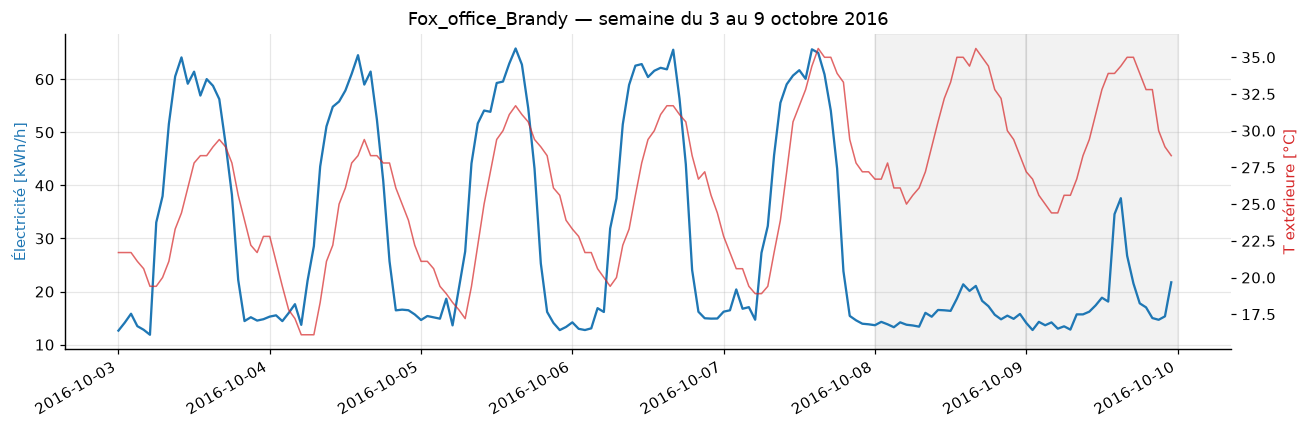

In [8]:
week = df.loc["2016-10-03":"2016-10-09"]  # lundi → dimanche, hors vacances

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(week.index, week["kwh"], color="tab:blue", lw=1.5)
ax1.set_ylabel("Électricité [kWh/h]", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(week.index, week["airTemperature"], color="tab:red", lw=1, alpha=0.7)
ax2.set_ylabel("T extérieure [°C]", color="tab:red")
ax2.grid(False)
for d in pd.date_range("2016-10-08", periods=2):  # week-end grisé
    ax1.axvspan(d, d + pd.Timedelta(days=1), color="grey", alpha=0.1)
ax1.set_title(f"{BUILDING} — semaine du 3 au 9 octobre 2016")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG / "01_semaine.png")

**Lecture** : talon nocturne bas, montée le matin à l'arrivée des occupants, plateau
en journée, et week-end proche du talon. Le pic de journée suit aussi la température :
en Arizona, la climatisation est électrique.

## 5. Une année complète

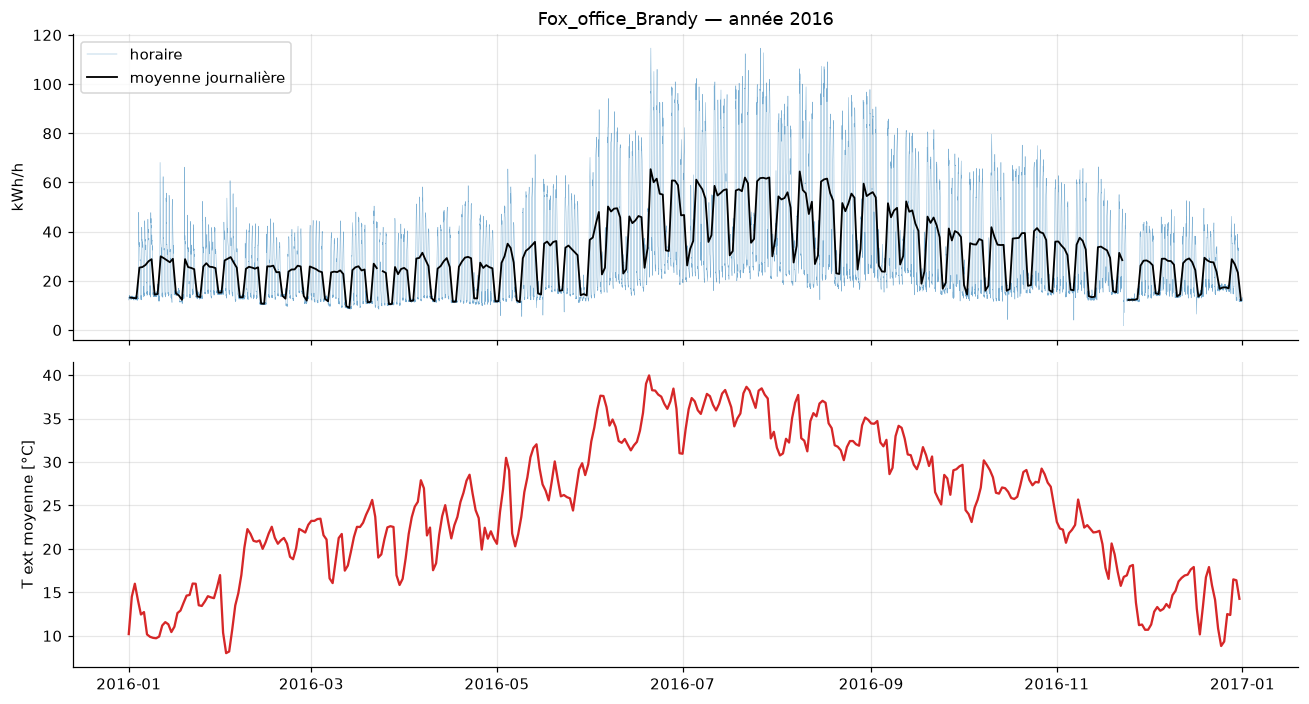

In [9]:
year = df.loc["2016"]
daily = year["kwh"].resample("D").sum(min_count=24)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(
    year.index, year["kwh"], lw=0.3, color="tab:blue", alpha=0.6, label="horaire"
)
axes[0].plot(
    daily.index + pd.Timedelta(hours=12),
    daily / 24,
    color="k",
    lw=1.2,
    label="moyenne journalière",
)
axes[0].set_ylabel("kWh/h")
axes[0].legend(loc="upper left")
axes[0].set_title(f"{BUILDING} — année 2016")
axes[1].plot(year["airTemperature"].resample("D").mean(), color="tab:red")
axes[1].set_ylabel("T ext moyenne [°C]")
fig.tight_layout()
fig.savefig(FIG / "01_annee.png")

## 6. Carte de chaleur heure × jour

Toute l'année d'un coup d'œil : chaque colonne est un jour, chaque ligne une heure.
On y repère les horaires d'occupation, les week-ends, les vacances, l'effet saisonnier
et les trous de données (en blanc).

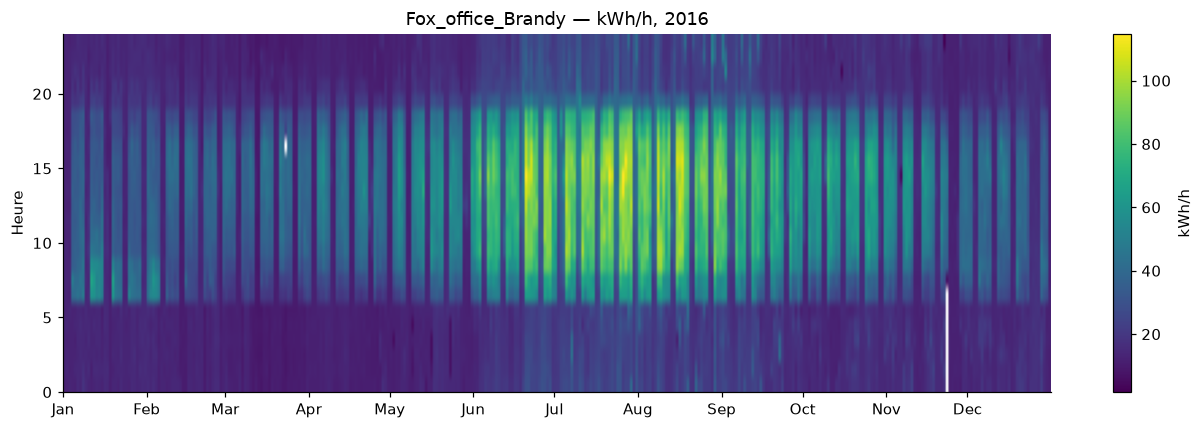

In [10]:
pivot = year.assign(date=year.index.date, hour=year.index.hour).pivot_table(
    index="hour", columns="date", values="kwh", dropna=False
)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(
    pivot,
    aspect="auto",
    cmap="viridis",
    origin="lower",
    extent=[0, pivot.shape[1], 0, 24],
)
months = pd.date_range("2016-01-01", "2016-12-01", freq="MS")
ax.set_xticks(
    [(m - pd.Timestamp("2016-01-01")).days for m in months],
    [m.strftime("%b") for m in months],
)
ax.set_ylabel("Heure")
ax.grid(False)
ax.set_title(f"{BUILDING} — kWh/h, 2016")
fig.colorbar(im, ax=ax, label="kWh/h")
fig.tight_layout()
fig.savefig(FIG / "01_heatmap.png")

## 7. Profils moyens par heure : semaine vs week-end, été vs hiver

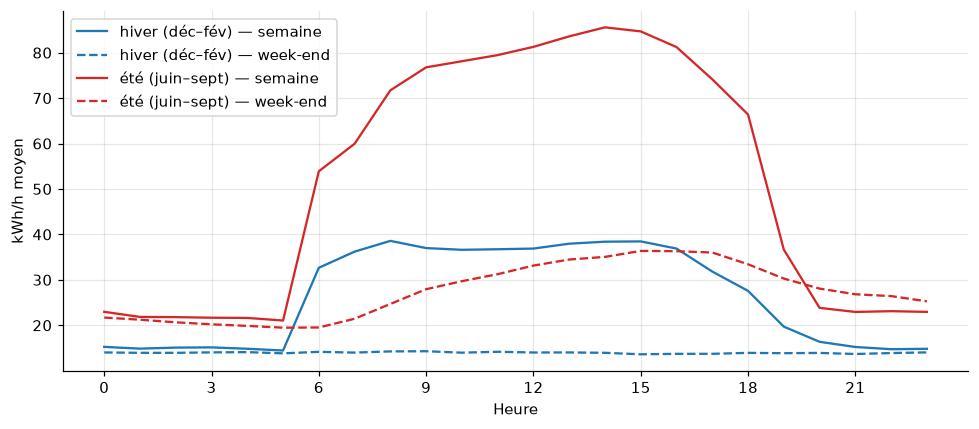

In [11]:
season = np.select(
    [df.index.month.isin([6, 7, 8, 9]), df.index.month.isin([12, 1, 2])],
    ["été (juin–sept)", "hiver (déc–fév)"],
    default="",
)
d = df.assign(hour=df.index.hour, weekend=df.index.day_of_week >= 5, saison=season)
prof = d[d["saison"] != ""].groupby(["saison", "weekend", "hour"])["kwh"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
for (saison, we), g in prof.groupby(level=[0, 1]):
    ax.plot(
        g.index.get_level_values("hour"),
        g.values,
        ls="--" if we else "-",
        color="tab:red" if "été" in saison else "tab:blue",
        label=f"{saison} — {'week-end' if we else 'semaine'}",
    )
ax.set_xlabel("Heure")
ax.set_ylabel("kWh/h moyen")
ax.set_xticks(range(0, 24, 3))
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_profils.png")

## 8. Signature énergétique : consommation vs température

En thermique du bâtiment, on trace la consommation journalière contre la température
moyenne journalière. Avec une clim électrique, on attend un **modèle à point
d'inflexion (change-point)** :
- en dessous d'une température d'équilibre, consommation ≈ constante (talon : éclairage,
  bureautique, ventilation) ;
- au-dessus, la consommation croît ~linéairement avec T (charge de refroidissement
  ∝ UA·(T_ext − T_int) + apports, divisée par le COP de la clim).

On sépare jours ouvrés et week-ends, sinon l'occupation brouille la relation.
On ne garde que les jours complets (24 h de mesure).

727 jours complets, dont 518 ouvrés


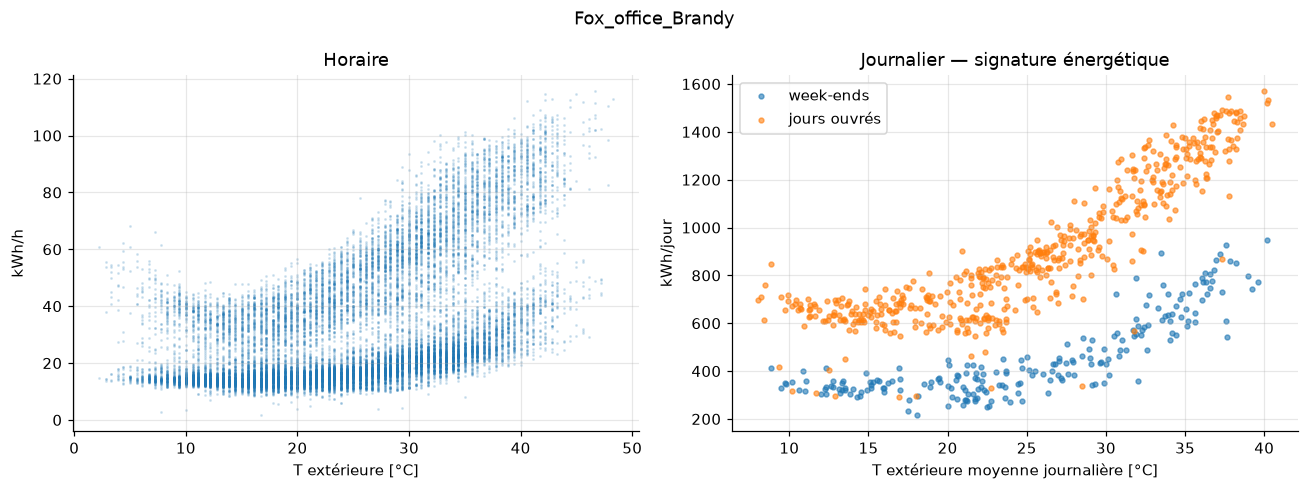

In [12]:
day = (
    df.resample("D")
    .agg({"kwh": lambda x: x.sum(min_count=24), "airTemperature": "mean"})
    .dropna()
)
day["ouvré"] = day.index.day_of_week < 5
print(f"{len(day)} jours complets, dont {day['ouvré'].sum()} ouvrés")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) nuage horaire
axes[0].scatter(df["airTemperature"], df["kwh"], s=1, alpha=0.15, color="tab:blue")
axes[0].set_xlabel("T extérieure [°C]")
axes[0].set_ylabel("kWh/h")
axes[0].set_title("Horaire")

# (b) signature journalière
for ouvre, g in day.groupby("ouvré"):
    axes[1].scatter(
        g["airTemperature"],
        g["kwh"],
        s=10,
        alpha=0.6,
        label="jours ouvrés" if ouvre else "week-ends",
    )
axes[1].set_xlabel("T extérieure moyenne journalière [°C]")
axes[1].set_ylabel("kWh/jour")
axes[1].set_title("Journalier — signature énergétique")
axes[1].legend()
fig.suptitle(BUILDING)
fig.tight_layout()
fig.savefig(FIG / "01_signature.png")

### Premier modèle physique : change-point 3P refroidissement

$E = \beta_0 + \beta_1 \cdot \max(0,\ T - T_c)$ — on cherche $T_c$ par balayage
et $\beta_0, \beta_1$ par moindres carrés (code dans `src/changepoint.py`).
C'est la forme standard de l'ASHRAE Guideline 14, qu'on réutilisera en semaine 5 (M&V).

**Métriques** (`src/metrics.py`) : le R² ne suffit pas. La Guideline 14 utilise :
- **CV(RMSE)** = RMSE / moyenne mesurée : l'erreur typique, en % de la consommation ;
- **NMBE** = biais moyen normalisé : le modèle sur- ou sous-estime-t-il en moyenne ?

Seuils G14 : CV(RMSE) ≤ 30 % et |NMBE| ≤ 10 % en horaire ; ≤ 15 % et ≤ 5 % en mensuel.
Ici, sur les données d'entraînement, le NMBE est nul par construction (régression
avec constante) : il deviendra informatif sur une période de test (semaines 2–5).

3PC | talon=646 | Tc=21.75 °C | pente froid=47.0
{'R2': np.float64(0.868), 'CV(RMSE) %': np.float64(11.6), 'NMBE %': np.float64(-0.0)}


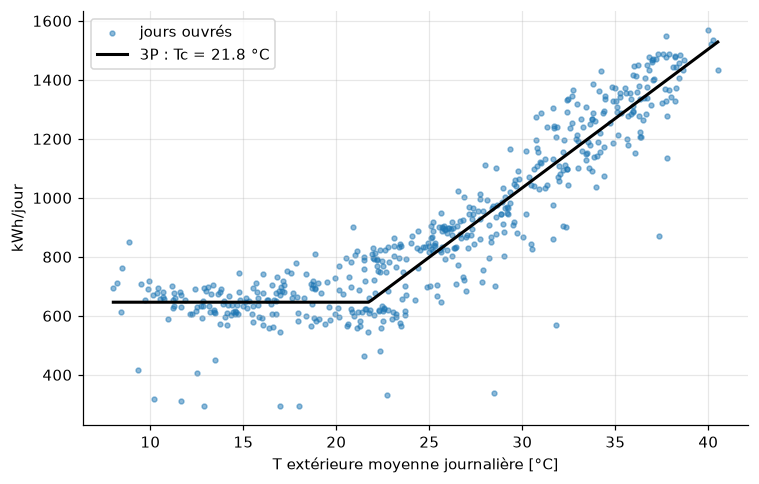

In [13]:
wd = day[day["ouvré"]]
m3 = changepoint.fit(wd["airTemperature"], wd["kwh"], kind="3PC")
wd = wd.assign(pred=m3.predict(wd["airTemperature"]))
wd["résidu"] = wd["kwh"] - wd["pred"]

print(m3)
print(report(wd["kwh"], wd["pred"], n_params=m3.n_params))

Tg = np.linspace(day["airTemperature"].min(), day["airTemperature"].max(), 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(wd["airTemperature"], wd["kwh"], s=10, alpha=0.5, label="jours ouvrés")
ax.plot(Tg, m3.predict(Tg), color="k", lw=2, label=f"3P : Tc = {m3.tc:.1f} °C")
ax.set_xlabel("T extérieure moyenne journalière [°C]")
ax.set_ylabel("kWh/jour")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_changepoint.png")

## 9. Les points bas : jours fériés et vacances

Quelques jours « ouvrés » tombent vers 300 kWh/j, très loin du modèle. Hypothèse :
jours fériés et vacances universitaires. On liste les jours ouvrés dont le résidu
est inférieur à −200 kWh et on les croise avec le calendrier des jours fériés
américains (bibliothèque `holidays`).

In [14]:
us_holidays = holidays.US(years=[2016, 2017])


def calendar_label(date):
    if date in us_holidays:
        return us_holidays[date]
    if (date - pd.Timedelta(days=1)) in us_holidays and "Thanksgiving" in us_holidays[
        date - pd.Timedelta(days=1)
    ]:
        return "Lendemain de Thanksgiving"
    if (date.month == 12 and date.day >= 20) or (date.month == 1 and date.day <= 5):
        return "Vacances d'hiver (université)"
    return ""


low = wd[wd["résidu"] < -200].copy()
low["calendrier"] = [calendar_label(d) for d in low.index]
low[["kwh", "airTemperature", "résidu", "calendrier"]].round(0)

,kwh,airTemperature,résidu,calendrier
timestamp,,,,
2016-01-01,318.0,10.0,-329.0,New Year's Day
2016-01-18,295.0,13.0,-352.0,Martin Luther King Jr. Day
2016-04-07,685.0,27.0,-206.0,
2016-04-21,714.0,28.0,-219.0,
2016-04-22,701.0,29.0,-264.0,
2016-05-04,842.0,30.0,-214.0,
2016-05-12,827.0,31.0,-232.0,
2016-05-13,861.0,32.0,-250.0,
2016-05-30,337.0,28.0,-626.0,Memorial Day


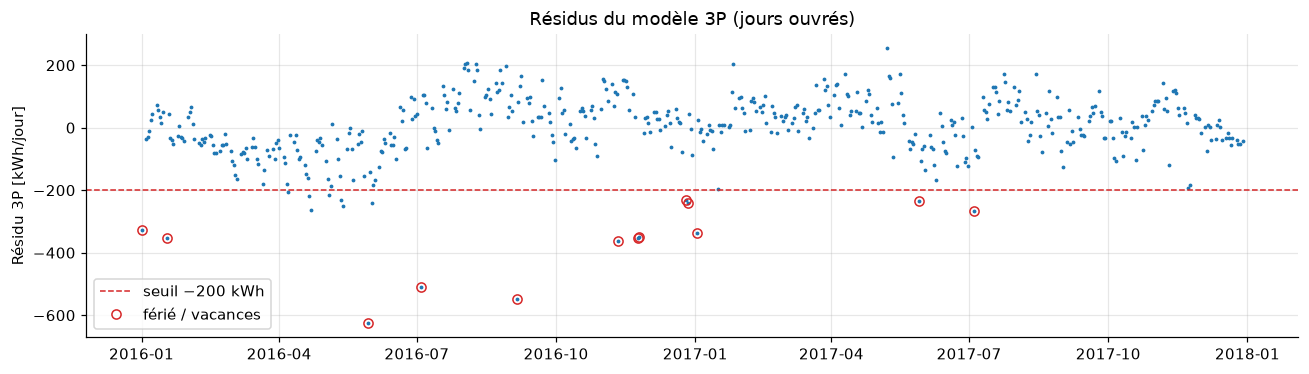

In [15]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(wd.index, wd["résidu"], ".", ms=3, color="tab:blue")
ax.axhline(-200, color="tab:red", ls="--", lw=1, label="seuil −200 kWh")
flag = low[low["calendrier"] != ""]
ax.plot(
    flag.index,
    flag["résidu"],
    "o",
    mfc="none",
    color="tab:red",
    label="férié / vacances",
)
ax.set_ylabel("Résidu 3P [kWh/jour]")
ax.set_title("Résidus du modèle 3P (jours ouvrés)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "01_residus.png")

**Lecture** :
- Les plus gros écarts (−300 à −600 kWh) sont tous des **jours fériés** : Nouvel An,
  Martin Luther King Day, Memorial Day, 4 juillet, Labor Day, Veterans Day,
  Thanksgiving et son lendemain, et les **vacances d'hiver** de l'université.
- Il reste quelques jours d'avril–mai avec un résidu d'environ −200 à −260 kWh qui ne
  sont pas fériés : probablement la fin du semestre universitaire, ou un modèle 3P
  imparfait en mi-saison.
- Les résidus ne sont **pas aléatoires** : plutôt négatifs au printemps, positifs en
  août–septembre. À température égale, le bâtiment consomme plus en fin d'été.
  Hypothèses : la **mousson** d'Arizona (juillet–septembre) augmente l'humidité, donc
  la charge latente de la clim, que la température sèche ne capte pas ; et le
  calendrier universitaire (rentrée en août).
- **Conséquences pour la semaine 3** : le modèle ML aura besoin d'une feature
  « jour férié / vacances » (sinon il confondra les vacances avec des anomalies), et
  il faudra tester le **point de rosée** comme variable météo.

## 10. Y a-t-il du chauffage électrique ? Comparaison 3P vs 5P

À basse température, quelques points semblent remonter légèrement. On teste un modèle
**5P** (chauffage + refroidissement) :

$E = \beta_0 + \beta_h \max(0,\ T_h - T) + \beta_c \max(0,\ T - T_c)$

On compare sur tous les jours ouvrés, puis en excluant les jours fériés et vacances
(identifiés **par le calendrier**, pas par les résidus, pour ne pas biaiser le test).

In [16]:
is_holiday = pd.Series([calendar_label(d) != "" for d in wd.index], index=wd.index)
datasets = {"tous les jours ouvrés": wd, "sans fériés / vacances": wd[~is_holiday]}

rows, models_clean = [], {}
for name, data in datasets.items():
    for kind in ["3PC", "5P"]:
        m = changepoint.fit(data["airTemperature"], data["kwh"], kind=kind)
        pred = m.predict(data["airTemperature"])
        rows.append(
            {
                "données": name,
                "modèle": kind,
                "n jours": len(data),
                "Th [°C]": m.th,
                "pente chauffage": m.coef[1] if kind == "5P" else np.nan,
                "Tc [°C]": m.tc,
                **report(data["kwh"], pred, n_params=m.n_params),
            }
        )
        if name.startswith("sans"):
            models_clean[kind] = m
comparison = pd.DataFrame(rows).round(2)
comparison

,données,modèle,n jours,Th [°C],pente chauffage,Tc [°C],R2,CV(RMSE) %,NMBE %
0,tous les jours ouvrés,3PC,518,NaN,NaN,21.75,0.87,11.6,-0.0
1,tous les jours ouvrés,5P,518,22.25,-4.38,22.50,0.87,11.6,-0.0
2,sans fériés / vacances,3PC,477,NaN,NaN,22.25,0.91,9.2,0.0
3,sans fériés / vacances,5P,477,11.00,31.65,21.75,0.91,9.2,0.0


Jours ouvrés (hors fériés) sous Th = 11.0 °C : 15


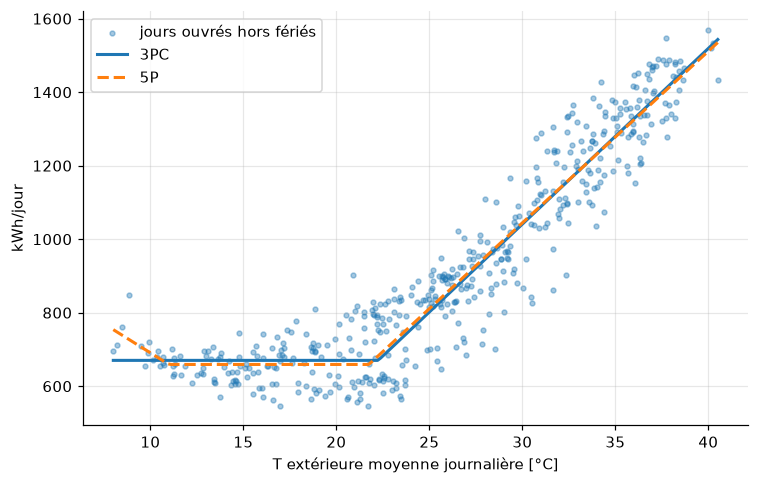

In [17]:
clean = wd[~is_holiday]
n_cold = (clean["airTemperature"] < models_clean["5P"].th).sum()
print(f"Jours ouvrés (hors fériés) sous Th = {models_clean['5P'].th:.1f} °C : {n_cold}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(
    clean["airTemperature"],
    clean["kwh"],
    s=10,
    alpha=0.4,
    label="jours ouvrés hors fériés",
)
for kind, ls in [("3PC", "-"), ("5P", "--")]:
    ax.plot(Tg, models_clean[kind].predict(Tg), ls=ls, lw=2, label=kind)
ax.set_xlabel("T extérieure moyenne journalière [°C]")
ax.set_ylabel("kWh/jour")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_3p_vs_5p.png")

**Conclusion** :
- Sur tous les jours ouvrés, le 5P trouve une pente de chauffage **négative**
  (physiquement absurde) et n'améliore pas le CV(RMSE) : les jours froids sont aussi
  les vacances d'hiver, qui tirent la consommation vers le bas.
- Une fois les fériés et vacances retirés, une pente de chauffage apparaît sous ~11 °C,
  mais elle repose sur une quinzaine de jours seulement et le CV(RMSE) est **identique**
  (9,2 % pour les deux modèles) : les 2 paramètres en plus n'apportent rien.
- En revanche, retirer les fériés fait passer le CV(RMSE) du 3P de 11,6 % à 9,2 % :
  **le calendrier compte plus que le chauffage**.
- **Le 3P refroidissement suffit** : pas de chauffage électrique significatif. C'est
  cohérent avec le climat doux de Tempe, les apports internes d'un bureau, et un
  chauffage probablement assuré par le réseau de chaleur du campus (non mesuré ici :
  68 bâtiments du site ont un compteur d'eau chaude, mais pas celui-ci).